
# Ejercicio 4: Descenso del gradiente

**Materia:** Matemáticas para Inteligencia Artificial

## Función del problema

$$
\begin{aligned}
f(x_1,x_2,x_3,x_4) ={}&
x_1^4+2x_2^4+3x_3^4+4x_4^4\\
&-4x_1-8x_2-12x_3-16x_4\\
&+(x_1-x_2)^2+(x_2-x_3)^2+(x_3-x_4)^2
\end{aligned}
$$

## Objetivo

Implementar el descenso del gradiente para encontrar el mínimo de la función.

Se probarán diferentes tasas de aprendizaje y puntos iniciales para seleccionar los parámetros de forma heurística.

El criterio de convergencia será:

$$
\|\nabla f(x_i)\| < 10^{-6}
$$

Se reportarán:

- Punto mínimo encontrado.
- Valor mínimo de la función.
- Gradiente final.
- Número de iteraciones.
- Gráfica de la función contra el número de iteraciones.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:

# Función matemática del ejercicio 4
def f(x):
    x1, x2, x3, x4 = x

    return (
        x1**4 + 2*x2**4 + 3*x3**4 + 4*x4**4
        - 4*x1 - 8*x2 - 12*x3 - 16*x4
        + (x1 - x2)**2
        + (x2 - x3)**2
        + (x3 - x4)**2
    )

# Punto inicial de prueba
x0 = np.array([0.0, 0.0, 0.0, 0.0])

print("Punto inicial:", x0)
print("Valor inicial de la función:", f(x0))


Punto inicial: [0. 0. 0. 0.]
Valor inicial de la función: 0.0



## Implementación del gradiente

Se calcula el gradiente mediante las cuatro derivadas parciales de la función:

$$
\nabla f(x)=
\begin{pmatrix}
4x_1^3-4+2(x_1-x_2)\\
8x_2^3-8-2(x_1-x_2)+2(x_2-x_3)\\
12x_3^3-12-2(x_2-x_3)+2(x_3-x_4)\\
16x_4^3-16-2(x_3-x_4)
\end{pmatrix}
$$

El gradiente indica la dirección de mayor crecimiento de la función. El descenso del gradiente utiliza su dirección contraria para buscar el mínimo.


In [5]:

# Gradiente de la función del ejercicio 4
def gradiente(x):
    x1, x2, x3, x4 = x

    df_dx1 = 4*x1**3 - 4 + 2*(x1 - x2)

    df_dx2 = 8*x2**3 - 8 - 2*(x1 - x2) + 2*(x2 - x3)

    df_dx3 = 12*x3**3 - 12 - 2*(x2 - x3) + 2*(x3 - x4)

    df_dx4 = 16*x4**3 - 16 - 2*(x3 - x4)

    return np.array([df_dx1, df_dx2, df_dx3, df_dx4])

# Evaluar el gradiente en el punto inicial
print("Gradiente inicial:", gradiente(x0))

# Calcular la norma del gradiente
print("Norma inicial:", np.linalg.norm(gradiente(x0)))


Gradiente inicial: [ -4.  -8. -12. -16.]
Norma inicial: 21.908902300206645



## Pruebas de convergencia

Se implementa el método de descenso del gradiente y se prueban diferentes tasas de aprendizaje y puntos iniciales.

El objetivo es observar si el algoritmo converge, oscila o diverge, para seleccionar los parámetros de forma heurística.

Se utilizará el criterio:

$$
\|\nabla f(x_i)\| < 10^{-6}
$$

Se establece un máximo de 10000 iteraciones para evitar ejecuciones indefinidas cuando los parámetros no permitan alcanzar la convergencia.


In [7]:

def descenso_gradiente(x_inicial, gamma, tolerancia=1e-6,
                       max_iteraciones=10000):

    x = np.array(x_inicial, dtype=float)
    historial = [f(x)]
    iteraciones = 0

    for i in range(max_iteraciones):

        g = gradiente(x)

        if np.linalg.norm(g) < tolerancia:
            return x, historial, iteraciones, "Convergió"

        nuevo_x = x - gamma * g

        # Detectar valores no finitos o crecimiento excesivo
        if (not np.all(np.isfinite(nuevo_x))
                or np.linalg.norm(nuevo_x) > 1e6):
            return x, historial, iteraciones, "Divergió"

        x = nuevo_x
        historial.append(f(x))
        iteraciones += 1

    return x, historial, iteraciones, "Límite alcanzado"


In [8]:

# Tasas de aprendizaje que vamos a probar
tasas = [0.001, 0.01, 0.05, 0.1, 0.5]

# Puntos iniciales de prueba
puntos = [
    np.array([0.0, 0.0, 0.0, 0.0]),
    np.array([1.0, 1.0, 1.0, 1.0]),
    np.array([-1.0, -1.0, -1.0, -1.0])
]

resultados_pruebas = []

for punto in puntos:
    for tasa in tasas:

        minimo, historial, n_iter, estado = descenso_gradiente(
            punto, tasa
        )

        resultados_pruebas.append({
            "Punto inicial": str(punto),
            "Gamma": tasa,
            "Estado": estado,
            "Iteraciones": n_iter,
            "f(x) final": f(minimo),
            "Norma gradiente": np.linalg.norm(gradiente(minimo))
        })

tabla_pruebas = pd.DataFrame(resultados_pruebas)

display(tabla_pruebas)


,Punto inicial,Gamma,Estado,Iteraciones,f(x) final,Norma gradiente
0,[0. 0. 0. 0.],0.001,Convergió,1299,-3.000000e+01,9.869416e-07
1,[0. 0. 0. 0.],0.010,Convergió,123,-3.000000e+01,9.540614e-07
2,[0. 0. 0. 0.],0.050,Límite alcanzado,10000,-2.603272e+01,2.129169e+01
3,[0. 0. 0. 0.],0.100,Divergió,4,1.166766e+23,1.129309e+18
4,[0. 0. 0. 0.],0.500,Divergió,2,1.118747e+15,1.088572e+12
5,[1. 1. 1. 1.],0.001,Convergió,0,-3.000000e+01,0.000000e+00
6,[1. 1. 1. 1.],0.010,Convergió,0,-3.000000e+01,0.000000e+00
7,[1. 1. 1. 1.],0.050,Convergió,0,-3.000000e+01,0.000000e+00
8,[1. 1. 1. 1.],0.100,Convergió,0,-3.000000e+01,0.000000e+00
9,[1. 1. 1. 1.],0.500,Convergió,0,-3.000000e+01,0.000000e+00



## Selección de parámetros

Después de probar diferentes tasas de aprendizaje y puntos iniciales, se seleccionaron los siguientes valores:

- Tasa de aprendizaje: $\gamma=0.01$
- Punto inicial: $x_0=(0,0,0,0)$
- Tolerancia: $10^{-6}$

**Justificación:**

La tasa de aprendizaje de 0.001 logró converger, pero necesitó 1299 iteraciones. Al utilizar 0.01, el algoritmo convergió en 123 iteraciones.

Con 0.05 no se alcanzó el criterio de convergencia dentro del límite establecido, mientras que con 0.1 y 0.5 se observó divergencia.

Por lo tanto, se eligió 0.01 porque permitió encontrar el mínimo con un menor número de iteraciones y cumpliendo la tolerancia solicitada.


In [9]:

# Parámetros seleccionados
gamma = 0.01
x0 = np.array([0.0, 0.0, 0.0, 0.0])

# Ejecutar descenso del gradiente
minimo, historial, iteraciones, estado = descenso_gradiente(
    x0, gamma
)

# Calcular resultados
valor_minimo = f(minimo)
gradiente_final = gradiente(minimo)
norma_final = np.linalg.norm(gradiente_final)

# Mostrar resultados
print("Estado:", estado)
print("Punto mínimo encontrado:", minimo)
print("Valor de f(x*):", valor_minimo)
print("Gradiente final:", gradiente_final)
print("Norma del gradiente:", norma_final)
print("Número de iteraciones:", iteraciones)
print("¿Cumple la tolerancia?", norma_final < 1e-6)


Estado: Convergió
Punto mínimo encontrado: [0.99999993 0.99999999 1.         1.        ]
Valor de f(x*): -29.999999999999968
Gradiente final: [-9.44591633e-07 -1.33697735e-07 -1.02165256e-08 -5.63155966e-10]
Norma del gradiente: 9.540613876482757e-07
Número de iteraciones: 123
¿Cumple la tolerancia? True



## Gráfica de convergencia

Se representa el comportamiento de la función objetivo durante las iteraciones del descenso del gradiente.

El eje horizontal representa el número de iteración y el eje vertical el valor de la función $f(x_i)$.


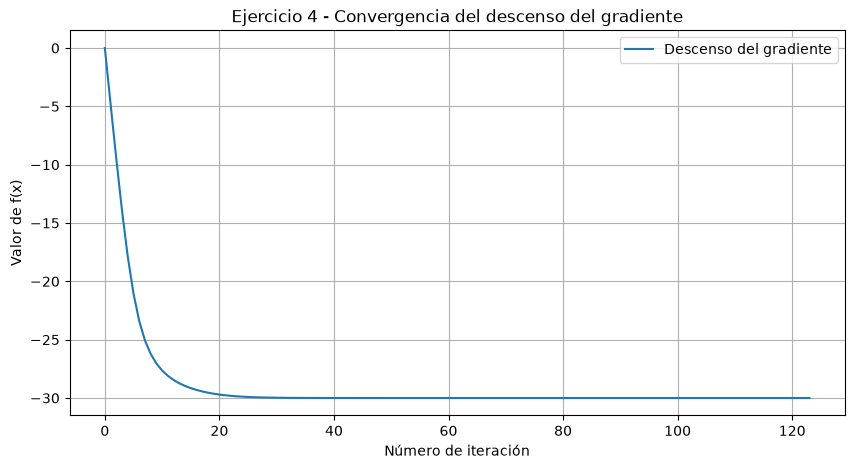

In [11]:

# Gráfica de convergencia
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(historial)),
    historial,
    label="Descenso del gradiente"
)

plt.xlabel("Número de iteración")
plt.ylabel("Valor de f(x)")
plt.title("Ejercicio 4 - Convergencia del descenso del gradiente")

plt.legend()
plt.grid(True)
plt.show()
